In [1]:
from glob import glob
import pandas as pd
import math
import random
import numpy as np

In [2]:
from glob import glob

In [3]:
audio_files=glob('C:/Users/HP/Desktop/Slope_Trial/S_T/'+'/*.wav')
len(audio_files)

1

# Merged wav files

In [4]:
# import required libraries
from pydub import AudioSegment
from pydub.playback import play 
sound1 = AudioSegment.from_file("C:/Users/HP/Desktop/Slope_Trial/S_T/sp1_ch2.wav" , "wav") 
# sound2 =AudioSegment.from_file("C:/Users/HP/Desktop/Slope_Trial/S_T/ReadingAssamese_1.wav" , "wav") 
# sound3 =AudioSegment.from_file("C:/Users/HP/Desktop/Slope_Trial/S_T/ReadingAssamese_2.wav" , "wav") 
  
# Combine the two audio files 
wav_file = sound1
   
# play the sound 
wav_file.export("MergeSound_ST.wav", format="wav")
sound4 =AudioSegment.from_file("MergeSound_ST.wav" , "wav") 


C:\Users\HP\anaconda3\lib\site-packages\pydub\utils.py:170: RuntimeWarning: Couldn't find ffmpeg or avconv - defaulting to ffmpeg, but may not work
  warn("Couldn't find ffmpeg or avconv - defaulting to ffmpeg, but may not work", RuntimeWarning)


# Segment the wav file

In [5]:
from pydub import AudioSegment
from pydub.utils import make_chunks

myaudio = AudioSegment.from_file("MergeSound_ST.wav" , "wav") 
chunk_length_ms = 2500 # pydub calculates in millisec
chunks = make_chunks(myaudio, chunk_length_ms) #Make chunks of one sec
#Export all of the individual chunks as wav files
# for i, chunk in enumerate(chunks):
#     chunk_name = "chunk{0}.wav".format(i)
#     print ("exporting", chunk_name)
#     chunk.export(chunk_name, format="wav")
  
for i, chunk in enumerate(chunks):
    chunk_name = "C:/Users/HP/Desktop/Slope_Trial/S_T/SegmentedAudio/chunk{0}.wav".format(i)
    print ("exporting", chunk_name)
    chunk.export(chunk_name, format="wav")

exporting C:/Users/HP/Desktop/Slope_Trial/S_T/SegmentedAudio/chunk0.wav
exporting C:/Users/HP/Desktop/Slope_Trial/S_T/SegmentedAudio/chunk1.wav
exporting C:/Users/HP/Desktop/Slope_Trial/S_T/SegmentedAudio/chunk2.wav
exporting C:/Users/HP/Desktop/Slope_Trial/S_T/SegmentedAudio/chunk3.wav
exporting C:/Users/HP/Desktop/Slope_Trial/S_T/SegmentedAudio/chunk4.wav
exporting C:/Users/HP/Desktop/Slope_Trial/S_T/SegmentedAudio/chunk5.wav
exporting C:/Users/HP/Desktop/Slope_Trial/S_T/SegmentedAudio/chunk6.wav
exporting C:/Users/HP/Desktop/Slope_Trial/S_T/SegmentedAudio/chunk7.wav
exporting C:/Users/HP/Desktop/Slope_Trial/S_T/SegmentedAudio/chunk8.wav
exporting C:/Users/HP/Desktop/Slope_Trial/S_T/SegmentedAudio/chunk9.wav
exporting C:/Users/HP/Desktop/Slope_Trial/S_T/SegmentedAudio/chunk10.wav
exporting C:/Users/HP/Desktop/Slope_Trial/S_T/SegmentedAudio/chunk11.wav
exporting C:/Users/HP/Desktop/Slope_Trial/S_T/SegmentedAudio/chunk12.wav
exporting C:/Users/HP/Desktop/Slope_Trial/S_T/SegmentedAudio/

In [6]:
data = pd.DataFrame()

In [7]:
import os
path = r"C:/Users/HP/Desktop/Slope_Trial/S_T/SegmentedAudio/" ## ENTER PATH OF FOLDER
files = os.listdir(path)

In [8]:
pip install praatio==4.2.0

Note: you may need to restart the kernel to use updated packages.


# Feature Extraction

In [9]:
import os
from os.path import join

from praatio import tgio
from praatio import pitch_and_intensity

praatEXE = r"C:/Users/HP/Desktop/Praat.exe"
pitch = r"C:/Users/HP/Desktop/pitch/pitch_ST.txt"

In [10]:
for file in files:
    if file.find('.wav') != -1:
        wav = os.path.join(path,file)
        pitchList = pitch_and_intensity.extractPitch(wav,pitch,
                                                     praatEXE, 50, 350,
                                                     forceRegenerate=True)
        intensityList = pitch_and_intensity.extractIntensity(wav,pitch,
                                                     praatEXE, 50,
                                                     forceRegenerate=True)
        
        #################### PITCH #####################################################
        
        sum1 = 0
        for i in range(0,len(pitchList)):
            sum1 = sum1 + pitchList[i][1]

        avg1 = sum1 / len(pitchList)

        max_pitch = pitchList[0][1]
        min_pitch = pitchList[0][1]
        for i in range(1,len(pitchList)):
            if pitchList[i][1]>max_pitch:
                max_pitch = pitchList[i][1]
                max_time  = pitchList[i][0]
            if pitchList[i][1]<min_pitch:
                min_pitch = pitchList[i][1]
                min_time  = pitchList[i][0]
                
        
        pitch_range = max_pitch - min_pitch  ### PITCH RANGE
        pitch_slope = pitch_range/(max_time - min_time)
        
        

        ################## INTENSITY #####################################################
        
        sum2 = 0
        for j in range(0,len(intensityList)):
            sum2 = sum2 + intensityList[i][1]

        avg2 = sum2 / len(intensityList)

        max_intensity = intensityList[0][1]
        min_intensity = intensityList[0][1]

        for i in range(1,len(intensityList)):
            if intensityList[i][1]>max_intensity:
                intensity = intensityList[i][1]
            if intensityList[i][1]<min_intensity:
                min_intensity = intensityList[i][1]  
        intensity_range = max_intensity - min_intensity  ### PITCH RANGE
        intensity_slope = intensity_range/(max_time - min_time)
        ################# SPEECH RATE AND SENTENCE DURATION ################################
        
#         p = file # Audio File title
#         #print('1st',p)
#         p = p.replace('.wav','')
#         #print('2nd',p)
#         c = path # Path to the Audio_File directory (Python 3.7)
#         #print(c)
#         t = myspsr(p,c) # rate of speech
#         m = myspod(p,c) # sentence duration


        
        
        df = pd.DataFrame({'Name':[file],'Pitch':[avg1],'MaxPitch':[max_pitch],'MinPitch':[min_pitch],'Intensity':[avg2],'MaxIntensity':[max_intensity],'MinIntensity':[min_intensity],
                           'Intensity_Range':[intensity_range],'Intensity Slope':[intensity_slope],'Pitch_Range':[pitch_range],'Pitch Slope':[pitch_slope]})
        data = data.append(df,ignore_index=True)
    else:
        continue
data    

,Name,Pitch,MaxPitch,MinPitch,Intensity,MaxIntensity,MinIntensity,Intensity_Range,Intensity Slope,Pitch_Range,Pitch Slope
0,chunk0.wav,211.048952,257.313142,168.778772,70.368849,35.810008,35.744222,0.065786,0.177801,88.534369,239.282079
1,chunk1.wav,212.792602,273.919517,152.685068,72.706064,83.537782,36.354148,47.183634,56.170993,121.234449,144.326725
2,chunk10.wav,210.165696,262.327013,177.070026,51.509431,76.302153,35.737715,40.564439,81.128877,85.256987,170.513974
3,chunk100.wav,222.083551,278.653438,173.386729,77.730437,66.996337,36.153749,30.842588,-42.836928,105.266709,-146.203762
4,chunk101.wav,196.221098,256.571697,151.336356,55.852693,59.024292,44.035591,14.988701,-21.110847,105.235340,-148.218789
...,...,...,...,...,...,...,...,...,...,...,...
602,chunk95.wav,231.948421,321.217249,165.450163,77.425341,74.030198,35.652597,38.377601,59.965001,155.767086,243.386072
603,chunk96.wav,231.708952,278.090050,182.202868,75.446089,35.608810,35.540309,0.068501,-0.062273,95.887182,-87.170165
604,chunk97.wav,216.062178,293.443058,90.455773,78.300044,64.435553,35.895949,28.539605,-12.354807,202.987285,-87.873284
605,chunk98.wav,220.384751,305.519589,171.096521,66.468079,36.891219,36.280044,0.611175,2.778069,134.423068,611.013943


In [11]:
data.to_csv('data.csv')

In [12]:
dt = pd.read_csv('data.csv')
dt

,Unnamed: 0,Name,Pitch,MaxPitch,MinPitch,Intensity,MaxIntensity,MinIntensity,Intensity_Range,Intensity Slope,Pitch_Range,Pitch Slope
0,0,chunk0.wav,211.048952,257.313142,168.778772,70.368849,35.810008,35.744222,0.065786,0.177801,88.534369,239.282079
1,1,chunk1.wav,212.792602,273.919517,152.685068,72.706064,83.537782,36.354148,47.183634,56.170993,121.234449,144.326725
2,2,chunk10.wav,210.165696,262.327013,177.070026,51.509431,76.302153,35.737715,40.564439,81.128877,85.256987,170.513974
3,3,chunk100.wav,222.083551,278.653438,173.386729,77.730437,66.996337,36.153749,30.842588,-42.836928,105.266709,-146.203762
4,4,chunk101.wav,196.221098,256.571697,151.336356,55.852693,59.024292,44.035591,14.988701,-21.110847,105.235340,-148.218789
...,...,...,...,...,...,...,...,...,...,...,...,...
602,602,chunk95.wav,231.948421,321.217249,165.450163,77.425341,74.030198,35.652597,38.377601,59.965001,155.767086,243.386072
603,603,chunk96.wav,231.708952,278.090050,182.202868,75.446089,35.608810,35.540309,0.068501,-0.062273,95.887182,-87.170165
604,604,chunk97.wav,216.062178,293.443058,90.455773,78.300044,64.435553,35.895949,28.539605,-12.354807,202.987285,-87.873284
605,605,chunk98.wav,220.384751,305.519589,171.096521,66.468079,36.891219,36.280044,0.611175,2.778069,134.423068,611.013943


In [13]:
dt.columns

Index(['Unnamed: 0', 'Name', 'Pitch', 'MaxPitch', 'MinPitch', 'Intensity',
       'MaxIntensity', 'MinIntensity', 'Intensity_Range', 'Intensity Slope',
       'Pitch_Range', 'Pitch Slope'],
      dtype='object')

# Setting up threshold values

In [14]:
#To identify average of all +ve slope values

PSlope=dt['Pitch Slope']
# print('Pitch Slope')
PSlope.to_csv("M_Slope.csv", index=False)

#Drop -ve pitch slope values
csvFile = pd.read_csv('M_Slope.csv')
SlopeDrop = csvFile[ (csvFile['Pitch Slope']<0)].index
#Droping mutiple rows based on column value
csvFile.drop(SlopeDrop,inplace=True) 
csvFile.to_csv("M_PositiveSlope.csv", index=False)
csvFile

,Pitch Slope
0,239.282079
1,144.326725
2,170.513974
5,103.537183
6,101.412279
...,...
597,113.315202
599,77.787910
602,243.386072
605,611.013943


In [15]:
dt
#High Intensity
import pandas as pd
H2=dt['MaxPitch']
H_Pch_Thr=H2.mean(axis=0)
#Low Intensity
L2=dt['MinPitch']
L_Pch_Thr=L2.max(axis=0)
#High Pitch
H1=dt['MaxIntensity']
H_Int_Thr=H1.mean(axis=0)
#Low Pitch
import pandas as pd
L1=dt['MinIntensity']
L_Int_Thr=L1.mean(axis=0)

#Slope using complete pitch slope column
Slope = pd.read_csv('M_PositiveSlope.csv')
S=dt['Pitch Slope']
S_Thr=S.mean(axis=0)
#S_Thr:Positive Slope threshold

#Slope using only +ve pitch slope values
PSlope = pd.read_csv('M_PositiveSlope.csv')
Sl=PSlope['Pitch Slope']
PS_Thr=Sl.mean(axis=0)
#S_Thr:Positive Slope threshold

#Intesity 
S1=dt['Intensity Slope']
IS_Thr=S1.mean(axis=0)


print("High Intensity Threshold:",H_Int_Thr,"\nLow Intensity Threshold:",L_Int_Thr,"\nHigh Pitch Threshold:",H_Pch_Thr,"\nLow Pitch Threshold:",L_Pch_Thr,"\nSlope Threshold:",S_Thr,"\nPositive Slope Threshold:",PS_Thr,"\nIntensity Threshold:",IS_Thr)
#S_Thr:Positive Slope threshold


High Intensity Threshold: 62.85385997523405 
Low Intensity Threshold: 36.80898532391343 
High Pitch Threshold: 281.12414496267326 
Low Pitch Threshold: 234.75712997389496 
Slope Threshold: 160.34655965132922 
Positive Slope Threshold: 826.3602292640527 
Intensity Threshold: 23.29674776913993


In [16]:
dt.columns
len(dt)

607

In [17]:
dF = dt.replace(['--undefined--'],0)
# df ['Unnamed: 12'] = df ['Unnamed: 12'].fillna (0)
# df ['Unnamed: 13'] = df ['Unnamed: 13'].fillna (0)
dict_from_csv =dF.to_dict()

print(dict_from_csv)
block = pd.DataFrame(dict_from_csv)
print("Original Data frame:\n",block)

#df['code'] = df['code'].astype(float)
# bl=block['f0Range_Hz'].astype(float)
#bl[0]#use bl[i] to set for loop
bl1=block['Intensity Slope'].astype(float)
bl2=block['Pitch Slope'].astype(float)
# bl=block['Pitch Slope'].astype(float)
len(dF)

{'Unnamed: 0': {0: 0, 1: 1, 2: 2, 3: 3, 4: 4, 5: 5, 6: 6, 7: 7, 8: 8, 9: 9, 10: 10, 11: 11, 12: 12, 13: 13, 14: 14, 15: 15, 16: 16, 17: 17, 18: 18, 19: 19, 20: 20, 21: 21, 22: 22, 23: 23, 24: 24, 25: 25, 26: 26, 27: 27, 28: 28, 29: 29, 30: 30, 31: 31, 32: 32, 33: 33, 34: 34, 35: 35, 36: 36, 37: 37, 38: 38, 39: 39, 40: 40, 41: 41, 42: 42, 43: 43, 44: 44, 45: 45, 46: 46, 47: 47, 48: 48, 49: 49, 50: 50, 51: 51, 52: 52, 53: 53, 54: 54, 55: 55, 56: 56, 57: 57, 58: 58, 59: 59, 60: 60, 61: 61, 62: 62, 63: 63, 64: 64, 65: 65, 66: 66, 67: 67, 68: 68, 69: 69, 70: 70, 71: 71, 72: 72, 73: 73, 74: 74, 75: 75, 76: 76, 77: 77, 78: 78, 79: 79, 80: 80, 81: 81, 82: 82, 83: 83, 84: 84, 85: 85, 86: 86, 87: 87, 88: 88, 89: 89, 90: 90, 91: 91, 92: 92, 93: 93, 94: 94, 95: 95, 96: 96, 97: 97, 98: 98, 99: 99, 100: 100, 101: 101, 102: 102, 103: 103, 104: 104, 105: 105, 106: 106, 107: 107, 108: 108, 109: 109, 110: 110, 111: 111, 112: 112, 113: 113, 114: 114, 115: 115, 116: 116, 117: 117, 118: 118, 119: 119, 120:

607

# Conditions for Stress identification

In [18]:
#using pitch slope
# print('auto_tone')
def func1():
    print('auto_stress')
    for i in range (len(dt)):
        if  bl1[i]<0 or bl2[i]<0 :
            print('U')
        elif bl2[i]<=H_Pch_Thr and bl2[i]>=L_Pch_Thr:
            print('S')
        elif bl1[i]<=H_Int_Thr and bl1[i]>=L_Int_Thr:
            print('S')
        elif bl2[i]>=L_Pch_Thr or bl1[i]>=L_Int_Thr:
            print('S')
        elif bl2[i]>=H_Pch_Thr or bl1[i]>=H_Int_Thr:
            print('S')
        elif bl1[i]<IS_Thr:
            print('U')
        elif (bl1[i]<=H_Int_Thr and bl1[i]>=IS_Thr):
            print('S')
        elif (bl2[i]<=H_Pch_Thr and bl2[i]>=PS_Thr):
            print('S')    
        else:
            print('Not an identical Tone')  
func1()

auto_stress
S
S
S
U
U
S
S
U
U
U
U
U
U
U
S
S
U
S
U
U
U
S
U
U
S
U
U
U
U
U
U
U
S
U
U
U
U
U
U
S
U
S
U
S
U
U
S
U
S
S
U
S
U
S
U
U
U
U
U
U
S
S
U
U
U
U
S
U
U
U
S
U
S
U
U
U
U
S
S
U
U
S
U
S
U
U
S
U
S
S
U
S
S
S
S
U
S
U
U
U
S
U
U
U
S
U
U
S
S
U
U
U
U
U
S
U
U
S
U
S
S
U
U
U
U
S
U
U
S
S
U
S
S
S
S
U
U
U
U
U
U
U
U
S
S
U
S
U
U
U
S
U
U
U
S
U
S
U
U
S
S
S
S
U
U
U
S
U
U
U
S
S
U
U
U
S
U
S
S
U
U
S
U
U
U
U
S
U
U
S
S
S
U
U
U
U
U
U
U
U
S
U
U
S
S
S
U
S
U
U
S
S
S
S
U
S
S
S
U
U
U
U
U
S
U
U
S
S
S
S
U
U
U
U
U
U
U
U
S
U
S
U
U
U
U
U
U
U
U
S
S
U
U
U
U
U
U
S
S
S
S
S
U
U
U
S
S
U
U
S
S
U
U
U
S
S
S
U
S
U
U
S
U
S
U
S
U
U
U
U
S
U
U
U
U
S
U
U
S
U
U
S
S
U
U
U
S
U
S
U
S
S
S
U
S
U
U
U
U
S
U
S
U
U
S
U
U
U
U
S
U
U
S
U
S
U
U
U
S
U
U
S
S
U
U
S
U
U
U
U
S
U
U
S
U
S
U
U
U
S
U
U
U
S
U
S
U
S
U
U
U
U
U
S
S
U
U
S
S
U
U
S
U
U
U
U
U
U
S
S
S
S
S
S
U
S
U
S
U
U
U
S
U
S
U
U
U
U
U
U
U
U
S
U
S
S
S
U
U
U
S
S
S
U
S
S
U
U
S
S
U
U
U
S
S
U
U
S
U
S
S
U
U
S
U
U
U
U
S
U
U
U
U
S
U
U
U
U
S
U
U
S
U
S
S
U
S
U
S
U
U
S
S
S
S
S
U
S
U
U
U
U
U
U
U
U
U
U
U
S
U
U
U
S


In [19]:
%%capture cap --no-stderr
func1()

In [20]:
#Store generated auto_tone into a new column
with open('output_S.csv', 'w') as f:
    f.write(cap.stdout)

# Conditions for Tone identification

In [21]:
# def func2():
#     print('auto_tone')
#     for i in range (len(dF)):
#         if  bl2[i]<0 :
#             print('F')
#         elif bl2[i]>PS_Thr :
#             print('R')
#         elif bl2[i]<L_Pch_Thr:
#             if bl2[i]<=bl2[i-1]:
#                 print('L')
#             else:
#                 if (bl2[i-1]<PS_Thr or bl2[i-1]>H_Pch_Thr) and (bl2[i+1]<PS_Thr or bl2[i+1]>H_Pch_Thr):
#                     print('H')
# #             elif bl[i-1]=='F' and bl[i+1]=='H':
#                 elif bl2[i-1]-S_Thr<0 and (bl2[i+1]<PS_Thr or bl2[i+1]>H_Pch_Thr):
#                     print('R')
#                 elif  bl2[i-1]<=L_Pch_Thr and (bl2[i+1]<PS_Thr or bl2[i+1]>H_Pch_Thr):
#                     print('R')
# #             elif bl[i-1]=='F' and bl[i+1]=='F':
#                 elif bl2[i-1]-S_Thr<0 and bl2[i+1]-S_Thr<0:
#                     print('L')
# #             elif bl[i-1]=='R' and bl[i+1]=='F':
#                 elif bl2[i-1]>PS_Thr and  bl2[i+1]<0:
#                     print('H')
# #             elif bl[i-1]=='F' and bl[i+1]=='H':
#                 elif bl2[i-1]-S_Thr<0 and (bl2[i+1]<PS_Thr or bl2[i+1]>H_Pch_Thr):
#                     print('R')
# #             elif bl[i-1]=='F' and bl[i+1]=='R':
#                 elif bl2[i-1]-S_Thr<0 and bl2[i+1]>PS_Thr:
#                     print('L')
#                 elif bl2[i-1]-S_Thr<0 and bl2[i+1]-S_Thr<0:
#                     print('L')
#                 elif bl2[i-1]-S_Thr<0 and bl2[i]<=L_Pch_Thr:
#                     print('L') 
#                 elif bl2[i-1]<L_Pch_Thr and bl2[i]<0:
#                     print('L') 
            
#         elif bl2[i]<PS_Thr or bl2[i]>H_Pch_Thr:
#             print('H') 
#         else:
#             print('Not an identical Tone')  
# func2()

In [28]:
 def func2():
    print('auto_tone')
    for i in range (len(dF)):
        if  bl2[i]<0 :
            print('F')     
        elif bl2[i]>PS_Thr :
            print('R')
        elif bl2[i]<L_Pch_Thr:
            print('L') 
        elif bl2[i]<=PS_Thr or bl2[i]>=H_Pch_Thr:
            print('H')
        else:
            if (bl2[i-1]<PS_Thr or bl2[i-1]>H_Pch_Thr) and (bl2[i+1]<PS_Thr or bl2[i+1]>H_Pch_Thr):
                print('H')
#             elif bl[i-1]=='F' and bl[i+1]=='H':
            elif bl2[i-1]-S_Thr<0 and (bl2[i+1]<PS_Thr or bl2[i+1]>H_Pch_Thr):
                print('R')
            elif  bl2[i-1]<=L_Pch_Thr and (bl2[i+1]<PS_Thr or bl2[i+1]>H_Pch_Thr):
                print('R')
#             elif bl[i-1]=='F' and bl[i+1]=='F':
            elif bl2[i-1]-S_Thr<0 and bl2[i+1]-S_Thr<0:
                print('L')
#             elif bl[i-1]=='R' and bl[i+1]=='F':
            elif bl2[i-1]>PS_Thr and  bl2[i+1]<0:
                print('H')
#             elif bl[i-1]=='F' and bl[i+1]=='H':
            elif bl2[i-1]-S_Thr<0 and (bl2[i+1]<PS_Thr or bl2[i+1]>H_Pch_Thr):
                print('R')
#             elif bl[i-1]=='F' and bl[i+1]=='R':
            elif bl2[i-1]-S_Thr<0 and bl2[i+1]>PS_Thr:
                print('L')
            elif bl2[i-1]-S_Thr<0 and bl2[i+1]-S_Thr<0:
                print('L')
            elif bl2[i-1]-S_Thr<0 and bl2[i]<=L_Pch_Thr:
                print('L') 
            elif bl2[i-1]<L_Pch_Thr and bl2[i]<0:
                print('L') 
func2()

auto_tone
H
L
L
F
F
L
L
F
F
F
F
F
F
F
H
R
L
R
L
L
F
L
F
F
H
F
F
F
F
L
F
F
H
F
F
F
F
L
F
H
F
L
F
H
F
F
L
L
H
R
L
L
F
L
F
F
F
F
F
L
H
L
F
L
F
F
L
F
F
F
H
F
H
L
F
F
F
L
H
F
L
H
F
H
L
L
H
F
L
L
F
L
R
L
L
F
L
F
F
F
H
F
L
F
R
F
F
L
L
F
F
F
F
F
L
L
F
H
F
L
L
F
F
L
F
H
F
F
H
L
F
H
H
L
H
L
F
F
F
F
F
F
F
R
H
F
R
L
F
F
H
L
F
F
H
F
L
F
F
R
L
L
L
F
F
F
L
F
F
F
L
H
F
F
F
L
F
R
L
L
F
R
F
F
F
F
H
F
F
L
L
L
L
F
L
L
F
F
F
F
H
F
F
L
L
H
F
H
F
F
H
L
R
H
L
L
L
H
F
F
F
F
L
H
F
F
H
H
H
H
L
F
F
F
L
F
F
L
R
F
H
F
F
F
L
F
F
L
F
L
H
F
L
F
F
F
L
L
H
H
H
H
F
F
F
H
H
F
L
L
H
L
F
F
R
L
H
F
H
L
L
L
F
H
F
H
L
F
F
L
H
F
F
F
L
R
F
F
R
L
F
L
L
F
F
F
L
F
R
L
H
L
L
L
H
F
L
F
F
H
F
H
F
F
R
F
F
F
F
R
F
L
H
F
H
F
F
F
H
F
F
R
H
F
L
L
L
L
L
F
L
F
F
L
L
L
F
L
F
H
F
F
F
H
F
L
L
H
F
F
F
F
F
H
L
F
F
H
R
L
L
H
F
L
F
F
F
F
H
H
L
L
L
L
F
R
F
H
F
L
F
L
F
H
F
L
F
F
F
F
L
F
H
L
L
R
L
F
F
F
R
L
H
F
R
R
F
F
H
R
F
F
F
L
H
F
L
H
L
L
L
F
F
H
F
F
F
L
L
L
L
L
L
H
F
F
L
F
H
F
F
R
F
R
H
F
R
L
L
F
F
H
L
H
R
R
L
L
F
L
L
F
F
L
F
F
F
L
F
R
F
L
F
L
L


In [29]:
%%capture cap --no-stderr
func2()

In [30]:
#Store generated auto_tone into a new column
with open('output_T.csv', 'w') as f:
    f.write(cap.stdout)

# Merge generated CSV Files

In [31]:
import os, glob
import pandas as pd

path = "C:/Users/HP/Desktop/Slope_Trial/S_T/*.wav"

In [32]:
import pandas as pd
a = pd.read_csv("data.csv")
b = pd.read_csv("output_S.csv")
b = b.dropna(axis=1)
merged = a.join(b)
merged.to_csv("Merged_S.csv", index=False)

In [33]:
a = pd.read_csv("Merged_S.csv")
b = pd.read_csv("output_T.csv")
# b = b.dropna(axis=1)
merged = a.join(b)
merged.to_csv("Merged_ST.csv", index=False)

dt = pd.read_csv('Merged_ST.csv')
dt


,Unnamed: 0,Name,Pitch,MaxPitch,MinPitch,Intensity,MaxIntensity,MinIntensity,Intensity_Range,Intensity Slope,Pitch_Range,Pitch Slope,auto_stress,auto_tone
0,0,chunk0.wav,211.048952,257.313142,168.778772,70.368849,35.810008,35.744222,0.065786,0.177801,88.534369,239.282079,S,H
1,1,chunk1.wav,212.792602,273.919517,152.685068,72.706064,83.537782,36.354148,47.183634,56.170993,121.234449,144.326725,S,L
2,2,chunk10.wav,210.165696,262.327013,177.070026,51.509431,76.302153,35.737715,40.564439,81.128877,85.256987,170.513974,S,L
3,3,chunk100.wav,222.083551,278.653438,173.386729,77.730437,66.996337,36.153749,30.842588,-42.836928,105.266709,-146.203762,U,F
4,4,chunk101.wav,196.221098,256.571697,151.336356,55.852693,59.024292,44.035591,14.988701,-21.110847,105.235340,-148.218789,U,F
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
602,602,chunk95.wav,231.948421,321.217249,165.450163,77.425341,74.030198,35.652597,38.377601,59.965001,155.767086,243.386072,S,H
603,603,chunk96.wav,231.708952,278.090050,182.202868,75.446089,35.608810,35.540309,0.068501,-0.062273,95.887182,-87.170165,U,F
604,604,chunk97.wav,216.062178,293.443058,90.455773,78.300044,64.435553,35.895949,28.539605,-12.354807,202.987285,-87.873284,U,F
605,605,chunk98.wav,220.384751,305.519589,171.096521,66.468079,36.891219,36.280044,0.611175,2.778069,134.423068,611.013943,S,H


In [34]:
dt.columns

Index(['Unnamed: 0', 'Name', 'Pitch', 'MaxPitch', 'MinPitch', 'Intensity',
       'MaxIntensity', 'MinIntensity', 'Intensity_Range', 'Intensity Slope',
       'Pitch_Range', 'Pitch Slope', 'auto_stress', 'auto_tone'],
      dtype='object')

In [35]:
# Convert csv column into list
stress = dt['auto_stress'].tolist()
tone = dt['auto_tone'].tolist()
print('Stress:', stress)
print('Tone:', tone)
dt['auto_tone'].unique

Stress: ['S', 'S', 'S', 'U', 'U', 'S', 'S', 'U', 'U', 'U', 'U', 'U', 'U', 'U', 'S', 'S', 'U', 'S', 'U', 'U', 'U', 'S', 'U', 'U', 'S', 'U', 'U', 'U', 'U', 'U', 'U', 'U', 'S', 'U', 'U', 'U', 'U', 'U', 'U', 'S', 'U', 'S', 'U', 'S', 'U', 'U', 'S', 'U', 'S', 'S', 'U', 'S', 'U', 'S', 'U', 'U', 'U', 'U', 'U', 'U', 'S', 'S', 'U', 'U', 'U', 'U', 'S', 'U', 'U', 'U', 'S', 'U', 'S', 'U', 'U', 'U', 'U', 'S', 'S', 'U', 'U', 'S', 'U', 'S', 'U', 'U', 'S', 'U', 'S', 'S', 'U', 'S', 'S', 'S', 'S', 'U', 'S', 'U', 'U', 'U', 'S', 'U', 'U', 'U', 'S', 'U', 'U', 'S', 'S', 'U', 'U', 'U', 'U', 'U', 'S', 'U', 'U', 'S', 'U', 'S', 'S', 'U', 'U', 'U', 'U', 'S', 'U', 'U', 'S', 'S', 'U', 'S', 'S', 'S', 'S', 'U', 'U', 'U', 'U', 'U', 'U', 'U', 'U', 'S', 'S', 'U', 'S', 'U', 'U', 'U', 'S', 'U', 'U', 'U', 'S', 'U', 'S', 'U', 'U', 'S', 'S', 'S', 'S', 'U', 'U', 'U', 'S', 'U', 'U', 'U', 'S', 'S', 'U', 'U', 'U', 'S', 'U', 'S', 'S', 'U', 'U', 'S', 'U', 'U', 'U', 'U', 'S', 'U', 'U', 'S', 'S', 'S', 'U', 'U', 'U', 'U', 'U', 'U', '

<bound method Series.unique of 0      H
1      L
2      L
3      F
4      F
      ..
602    H
603    F
604    F
605    H
606    H
Name: auto_tone, Length: 607, dtype: object>

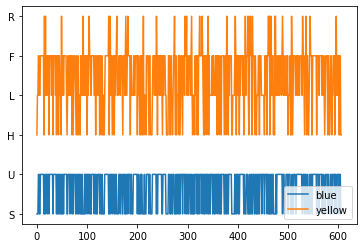

In [36]:

# importing modules
import numpy as np
import matplotlib.pyplot as plt
  
# # Y-axis values
# y1 = [2, 3, 4.5]
  
# # Y-axis values 
# y2 = [1, 1.5, 5]
  
# Function to plot  
plt.plot(stress)
plt.plot(tone)
  
# Function add a legend  
plt.legend(["blue", "yellow"], loc ="lower right")
  
# function to show the plot
plt.show()

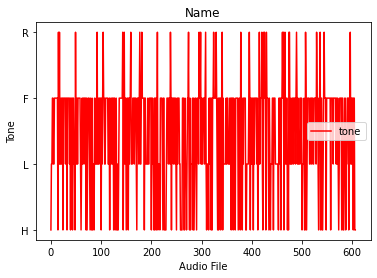

In [37]:

import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px

x=dt['auto_tone'].iloc[0:].values
# fig=plt.figure(figsize=(40.8, 20.8))
fig=plt.figure()
ax=fig.add_subplot(111)
ax.set_title("Name")
ax.set_xlabel("Audio File")
ax.set_ylabel("Tone")
ax.plot(x,c='r',label="tone")
leg=ax.legend()
plt.show()



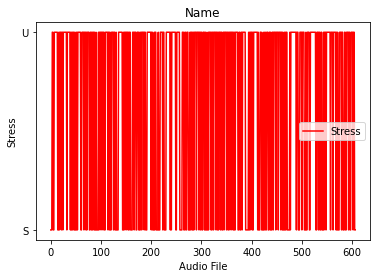

In [38]:

import plotly.express as px

x=dt['auto_stress'].iloc[0:].values
# fig=plt.figure(figsize=(40.8, 20.8))
fig=plt.figure()
ax=fig.add_subplot(111)
ax.set_title("Name")
ax.set_xlabel("Audio File")
ax.set_ylabel("Stress")
ax.plot(x,c='r',label="Stress")
leg=ax.legend()
plt.show()



In [39]:
# Convert csv column into list
stress = dt['auto_stress'].tolist()
tone = dt['auto_tone'].tolist()
print('Stress:', stress)
print('Tone:', tone)
dt['auto_tone'].unique

Stress: ['S', 'S', 'S', 'U', 'U', 'S', 'S', 'U', 'U', 'U', 'U', 'U', 'U', 'U', 'S', 'S', 'U', 'S', 'U', 'U', 'U', 'S', 'U', 'U', 'S', 'U', 'U', 'U', 'U', 'U', 'U', 'U', 'S', 'U', 'U', 'U', 'U', 'U', 'U', 'S', 'U', 'S', 'U', 'S', 'U', 'U', 'S', 'U', 'S', 'S', 'U', 'S', 'U', 'S', 'U', 'U', 'U', 'U', 'U', 'U', 'S', 'S', 'U', 'U', 'U', 'U', 'S', 'U', 'U', 'U', 'S', 'U', 'S', 'U', 'U', 'U', 'U', 'S', 'S', 'U', 'U', 'S', 'U', 'S', 'U', 'U', 'S', 'U', 'S', 'S', 'U', 'S', 'S', 'S', 'S', 'U', 'S', 'U', 'U', 'U', 'S', 'U', 'U', 'U', 'S', 'U', 'U', 'S', 'S', 'U', 'U', 'U', 'U', 'U', 'S', 'U', 'U', 'S', 'U', 'S', 'S', 'U', 'U', 'U', 'U', 'S', 'U', 'U', 'S', 'S', 'U', 'S', 'S', 'S', 'S', 'U', 'U', 'U', 'U', 'U', 'U', 'U', 'U', 'S', 'S', 'U', 'S', 'U', 'U', 'U', 'S', 'U', 'U', 'U', 'S', 'U', 'S', 'U', 'U', 'S', 'S', 'S', 'S', 'U', 'U', 'U', 'S', 'U', 'U', 'U', 'S', 'S', 'U', 'U', 'U', 'S', 'U', 'S', 'S', 'U', 'U', 'S', 'U', 'U', 'U', 'U', 'S', 'U', 'U', 'S', 'S', 'S', 'U', 'U', 'U', 'U', 'U', 'U', '

<bound method Series.unique of 0      H
1      L
2      L
3      F
4      F
      ..
602    H
603    F
604    F
605    H
606    H
Name: auto_tone, Length: 607, dtype: object>

In [40]:
import pandas as pd
dt = pd.read_csv('Merged_ST.csv')
dt1=dt.head(20)
# Convert csv column into list
stress1 = dt1['auto_stress'].tolist()
tone1 = dt1['auto_tone'].tolist()
print('Stress:', stress1)
print('Tone:', tone1)
dt1['auto_tone'].unique


Stress: ['S', 'S', 'S', 'U', 'U', 'S', 'S', 'U', 'U', 'U', 'U', 'U', 'U', 'U', 'S', 'S', 'U', 'S', 'U', 'U']
Tone: ['H', 'L', 'L', 'F', 'F', 'L', 'L', 'F', 'F', 'F', 'F', 'F', 'F', 'F', 'H', 'R', 'L', 'R', 'L', 'L']


<bound method Series.unique of 0     H
1     L
2     L
3     F
4     F
5     L
6     L
7     F
8     F
9     F
10    F
11    F
12    F
13    F
14    H
15    R
16    L
17    R
18    L
19    L
Name: auto_tone, dtype: object>

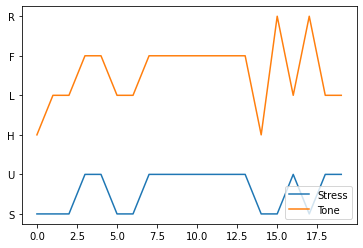

In [41]:
import numpy as np
import matplotlib.pyplot as plt
# importing modules
import numpy as np
# Function to plot  
plt.plot(stress1)
plt.plot(tone1) 
# Function add a legend  
plt.legend(["Stress", "Tone"], loc ="lower right")
# function to show the plot
plt.show()